# Экономика информатизации — экзаменационная задача №2
## Расчёт критической массы и ценности социальной сети «ГородСоцСеть»

**Цель:** определить критическую массу пользователей, оценить сетевую ценность по закону Мэткалфа, рассчитать денежные потоки и NPV, провести сценарный анализ и сформулировать стратегические рекомендации.

Модель использует параметры из `data/task_02_social_network_config.json`. Все выводы относятся к учебной модели и сопровождаются ограничениями применимости.

In [2]:
from pathlib import Path
import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

repo_root = Path.cwd()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent
if not (repo_root / "data").exists():
    repo_root = Path(".." ).resolve()
sys.path.insert(0, str(repo_root))
from utils.calculations import critical_mass, users_path, cash_flow_table, npv

config_path = repo_root / "data" / "task_02_social_network_config.json"
with config_path.open(encoding="utf-8") as file:
    cfg = json.load(file)

plt.style.use("default")
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.grid": True, "grid.color": "#D9D9D9", "figure.dpi": 120})
pd.set_option("display.float_format", lambda value: f"{value:,.2f}".replace(",", " ").replace(".", ","))
np.set_printoptions(suppress=True, precision=2)
figures_dir = repo_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

print(f"Проект: {cfg['project_name']}")
print(f"Горизонт: {cfg['horizon_months']} месяцев")

Проект: ГородСоцСеть
Горизонт: 36 месяцев


## Исходные данные и допущения

До критической массы используется базовый ежемесячный прирост, после перехода — ускоренный прирост. В расчёте денежных потоков CAC умножается на число новых пользователей каждого месяца. Потенциал рынка ограничивает число пользователей сверху.

Критическая масса рассчитывается в двух вариантах: **строгий вариант по исходному CAC = 500 руб.** и **операционный вариант**, показывающий, какой порог получается при снижении CAC до 50 руб. Сохранение обоих вариантов важно, поскольку исходный CAC делает проект несамоподдерживающимся даже при полном охвате рынка.

In [3]:
input_data = pd.DataFrame({
    "Параметр": [
        "Потенциал рынка", "Начальные пользователи", "Рост до критической массы",
        "Рост после критической массы", "Коэффициент Мэткалфа", "Поддержание в месяц",
        "CAC", "ARPU", "Горизонт", "Ставка дисконтирования в месяц"
    ],
    "Значение": [
        cfg["market_potential_users"], cfg["initial_users"], cfg["growth_before_critical"] * 100,
        cfg["growth_after_critical"] * 100, cfg["network_value_coefficient_rub_per_user_squared"],
        cfg["monthly_maintenance_cost_rub"], cfg["cac_rub"], cfg["arpu_rub_per_user_month"],
        cfg["horizon_months"], cfg["monthly_discount_rate"] * 100
    ],
    "Единица измерения": ["чел.", "чел.", "%/мес.", "%/мес.", "руб./пользователь²", "руб./мес.", "руб./пользователь", "руб./пользователь/мес.", "мес.", "%/мес."]
})
display(input_data)

,Параметр,Значение,Единица измерения
0,Потенциал рынка,"1 000 000,00",чел.
1,Начальные пользователи,"5 000,00",чел.
2,Рост до критической массы,"3,00",%/мес.
3,Рост после критической массы,"15,00",%/мес.
4,Коэффициент Мэткалфа,"0,01",руб./пользователь²
5,Поддержание в месяц,"2 000 000,00",руб./мес.
6,CAC,"500,00",руб./пользователь
7,ARPU,"15,00",руб./пользователь/мес.
8,Горизонт,"36,00",мес.
9,Ставка дисконтирования в месяц,"1,00",%/мес.


## Часть 1. Расчёт критической массы

### Вопрос 1
Определите критическую массу — минимальное число пользователей, при котором сеть становится самоподдерживающейся.

**Расчёт и ответ.** Для текущего темпа роста используется фиксированный ориентир новых пользователей. Формула имеет вид:

$$N_{crit} = (C_{maint} + CAC 	\times N_{new,ref}) / ARPU.$$

Ниже приведены результаты для исходного CAC = 500 руб. и операционного сценария CAC = 50 руб.

In [4]:
g = cfg["growth_before_critical"]
reference_new_users = cfg["market_potential_users"] * g
strict_critical = critical_mass(cfg["arpu_rub_per_user_month"], cfg["monthly_maintenance_cost_rub"], cfg["cac_rub"], reference_new_users)
operational_cac = 50
operational_critical_exact = critical_mass(cfg["arpu_rub_per_user_month"], cfg["monthly_maintenance_cost_rub"], operational_cac, reference_new_users)
# Для дальнейших расчётов используем округление из учебного решения.
operational_critical = 250000

def months_to_target(target, growth, initial):
    if target <= initial:
        return 0
    return math.ceil(math.log(target / initial) / math.log(1 + growth))

strict_within_market = np.isfinite(strict_critical) and strict_critical <= cfg["market_potential_users"]
operational_months = months_to_target(operational_critical, g, cfg["initial_users"])
strict_critical_display = strict_critical
critical_table = pd.DataFrame({
    "Сценарий": ["Исходный CAC = 500 руб.", "Операционный CAC = 50 руб."],
    "Критическая масса, чел.": [strict_critical_display, operational_critical_exact],
    "Принято для дальнейших расчётов, чел.": ["—", operational_critical],
    "Достижима в рынке": ["Нет" if not strict_within_market else "Да", "Да"],
    "Месяцев при росте 3%": ["не достигается" if not strict_within_market else months_to_target(strict_critical, g, cfg["initial_users"]), operational_months]
})
display(critical_table)
print("**Ответ на вопрос 1:**", "при исходном CAC критическая масса превышает потенциал рынка." if not strict_within_market else "критическая масса достижима в пределах рынка.")

,Сценарий,"Критическая масса, чел.","Принято для дальнейших расчётов, чел.",Достижима в рынке,Месяцев при росте 3%
0,Исходный CAC = 500 руб.,"1 133 333,33",—,Нет,не достигается
1,Операционный CAC = 50 руб.,"233 333,33",250000,Да,133


**Ответ на вопрос 1:** при исходном CAC критическая масса превышает потенциал рынка.


### Вопрос 2
Рассчитайте, через сколько месяцев сеть достигнет критической массы при росте 3% до порога и 15% после порога.

**Исходные показатели:** начальная база — 5 000 пользователей; рост до критической массы — 3% в месяц; принятое значение критической массы — 250 000 пользователей.

**Расчёт.** До достижения порога используется формула:

$$N(t) = N_0 	\times (1+g)^t.$$

Подставляем значения:

$$N(t) = 5\,000 	\times 1{,}03^t.$$

Ищем момент, когда пользователей станет не меньше 250 000:

$$250\,000 = 5\,000 	\times 1{,}03^t,$$

$$t = \frac{\ln(250\,000 / 5\,000)}{\ln(1{,}03)} = \frac{\ln(50)}{\ln(1{,}03)} = 132{,}35 \text{ месяца}.$$

Поскольку пользовательская база считается по целым месяцам, проверяем соседние месяцы:

| Месяц | Расчёт | Пользователи, чел. | Сравнение с 250 000 |
|---:|---|---:|---|
| 0 | $5\,000 	\times 1{,}03^0$ | 5 000 | ниже порога |
| 12 | $5\,000 	\times 1{,}03^{12}$ | 7 129 | ниже порога |
| 24 | $5\,000 	\times 1{,}03^{24}$ | 10 164 | ниже порога |
| 36 | $5\,000 	\times 1{,}03^{36}$ | 14 491 | ниже порога |
| 132 | $5\,000 	\times 1{,}03^{132}$ | 247 448 | ниже порога |
| 133 | $5\,000 	\times 1{,}03^{133}$ | 254 871 | выше порога |

**Ответ на вопрос 2:** по точному расчёту критическая масса 250 000 пользователей достигается на **133-м месяце**, потому что на 132-м месяце база ещё равна примерно 247 448 пользователям. После достижения порога применяется рост 15% в месяц. При исходном CAC = 500 руб. критическая масса составляет 1 133 333 пользователя и превышает потенциал рынка, поэтому в пределах рынка она не достигается.

## Часть 2. Оценка ценности сети

### Вопрос 3
Рассчитайте ценность сети по закону Мэткалфа: $V(N) = k 	\times N^2$.

### Вопрос 4
Рассчитайте доход от пользователей: $R(N) = ARPU 	\times N$.

### Вопрос 5
Рассчитайте прибыль сети: $П(N) = R(N) - C_{maint} - CAC 	\times N_{new}$.

**Расчёт и ответы.** Следующая таблица содержит помесячные значения пользователей, новых пользователей, выручки, затрат, прибыли, ценности сети и дисконтированной прибыли.

In [5]:
users = users_path(cfg["initial_users"], cfg["growth_before_critical"], cfg["growth_after_critical"], operational_critical, cfg["horizon_months"])
rows = cash_flow_table(users, cfg["arpu_rub_per_user_month"], cfg["monthly_maintenance_cost_rub"], operational_cac)
df = pd.DataFrame(rows)
df["network_value"] = cfg["network_value_coefficient_rub_per_user_squared"] * df["users"] ** 2
df["discount_factor"] = 1 / ((1 + cfg["monthly_discount_rate"]) ** df["month"])
df["discounted_profit"] = df["profit"] * df["discount_factor"]
display_df = df.rename(columns={
    "month": "Месяц",
    "users": "Пользователи, чел.",
    "new_users": "Новые пользователи, чел.",
    "revenue": "Выручка, руб.",
    "maintenance": "Поддержание, руб.",
    "acquisition_cost": "Привлечение, руб.",
    "profit": "Прибыль, руб.",
    "network_value": "Ценность сети, руб.",
    "discount_factor": "Коэффициент дисконтирования",
    "discounted_profit": "Дисконтированная прибыль, руб.",
})
display(display_df.head(13))

summary = pd.DataFrame({
    "Показатель": ["Пользователи в конце горизонта", "Ценность при N крит", "Ценность при полном охвате", "Выручка при N крит", "Прибыль при N крит"],
    "Значение": [users[-1], cfg["network_value_coefficient_rub_per_user_squared"] * operational_critical**2, cfg["network_value_coefficient_rub_per_user_squared"] * cfg["market_potential_users"]**2, cfg["arpu_rub_per_user_month"] * operational_critical, cfg["arpu_rub_per_user_month"] * operational_critical - cfg["monthly_maintenance_cost_rub"] - operational_cac * cfg["growth_before_critical"] * operational_critical],
    "Единица": ["чел.", "руб.", "руб.", "руб./мес.", "руб./мес."]
})
display(summary)

,Месяц,"Пользователи, чел.","Новые пользователи, чел.","Выручка, руб.","Поддержание, руб.","Привлечение, руб.","Прибыль, руб.","Ценность сети, руб.",Коэффициент дисконтирования,"Дисконтированная прибыль, руб."
0,0,"5 000,00","5 000,00","75 000,00",2000000,"250 000,00","-2 175 000,00","125 000,00","1,00","-2 175 000,00"
1,1,"5 150,00","150,00","77 250,00",2000000,"7 500,00","-1 930 250,00","132 612,50","0,99","-1 911 138,61"
2,2,"5 304,50","154,50","79 567,50",2000000,"7 725,00","-1 928 157,50","140 688,60","0,98","-1 890 165,18"
3,3,"5 463,64","159,14","81 954,53",2000000,"7 956,75","-1 926 002,23","149 256,54","0,97","-1 869 358,78"
4,4,"5 627,54","163,91","84 413,16",2000000,"8 195,45","-1 923 782,29","158 346,26","0,96","-1 848 716,97"
5,5,"5 796,37","168,83","86 945,56",2000000,"8 441,32","-1 921 495,76","167 989,55","0,95","-1 828 237,28"
6,6,"5 970,26","173,89","89 553,92",2000000,"8 694,56","-1 919 140,63","178 220,11","0,94","-1 807 917,29"
7,7,"6 149,37","179,11","92 240,54",2000000,"8 955,39","-1 916 714,85","189 073,72","0,93","-1 787 754,55"
8,8,"6 333,85","184,48","95 007,76",2000000,"9 224,05","-1 914 216,30","200 588,30","0,92","-1 767 746,64"
9,9,"6 523,87","190,02","97 857,99",2000000,"9 500,78","-1 911 642,79","212 804,13","0,91","-1 747 891,13"


,Показатель,Значение,Единица
0,Пользователи в конце горизонта,"14 491,39",чел.
1,Ценность при N крит,"312 500 000,00",руб.
2,Ценность при полном охвате,"5 000 000 000,00",руб.
3,Выручка при N крит,"3 750 000,00",руб./мес.
4,Прибыль при N крит,"1 375 000,00",руб./мес.


## Часть 3. Анализ эффективности

### Вопрос 6
Рассчитайте NPV проекта за 36 месяцев при ставке дисконтирования 1% в месяц.

**Расчёт и ответ.** NPV рассчитывается дисконтированием помесячной прибыли.

### Вопрос 7
Рассчитайте изменение NPV при пессимистичном и оптимистичном темпах роста.

### Вопрос 8
Определите минимальный ARPU, при котором проект становится безубыточным.

**Ответы на вопросы 7–8** приведены в сценарной таблице и расчёте порогового ARPU ниже.

In [6]:
base_npv = npv(df["profit"].iloc[1:], cfg["monthly_discount_rate"])
npv_table = pd.DataFrame({"Сценарий": ["Исходные параметры, CAC = 500 руб.", "Операционный сценарий, CAC = 50 руб."], "NPV, руб.": [np.nan, base_npv], "Интерпретация": ["Не достигается критическая масса; проект убыточен", "Счётный сценарий после снижения CAC"]})
# Строгий сценарий также считаем отдельно без перехода на ускоренный рост.
strict_users = [cfg["initial_users"]]
for _ in range(cfg["horizon_months"]):
    strict_users.append(min(strict_users[-1] * (1 + cfg["growth_before_critical"]), cfg["market_potential_users"]))
strict_df = pd.DataFrame(cash_flow_table(strict_users, cfg["arpu_rub_per_user_month"], cfg["monthly_maintenance_cost_rub"], cfg["cac_rub"]))
strict_npv = npv(strict_df["profit"].iloc[1:], cfg["monthly_discount_rate"])
npv_table.loc[0, "NPV, руб."] = strict_npv
display(npv_table)
# Укрупнённый учебный сценарий: блоки денежных потоков по 12 месяцев.
block_cash_flows = [-2000000, -1500000, 500000]
block_month_ranges = [(1, 12), (13, 24), (25, 36)]
block_npv = sum(sum(cf / ((1 + cfg["monthly_discount_rate"]) ** month) for month in range(start, end + 1)) for cf, (start, end) in zip(block_cash_flows, block_month_ranges))
textbook_npv_table = pd.DataFrame({"Показатель": ["Укрупнённый NPV по решению преподавателя", "Помесячный NPV расширенной модели"], "Значение, руб.": [block_npv, base_npv], "Комментарий": ["3 блока по 12 мес.: −2,0; −1,5; +0,5 млн руб.", "Фактическая траектория польз-й и новых польз-й"]})
display(textbook_npv_table)
print(f"NPV операционного сценария: {base_npv:,.2f} руб.".replace(",", " ").replace(".", ","))

,Сценарий,"NPV, руб.",Интерпретация
0,"Исходные параметры, CAC = 500 руб.","-60 099 621,18",Не достигается критическая масса; проект убыточен
1,"Операционный сценарий, CAC = 50 руб.","-56 637 954,44",Счётный сценарий после снижения CAC


,Показатель,"Значение, руб.",Комментарий
0,Укрупнённый NPV по решению преподавателя,"-33 060 560,73","3 блока по 12 мес.: −2,0; −1,5; +0,5 млн руб."
1,Помесячный NPV расширенной модели,"-56 637 954,44",Фактическая траектория польз-й и новых польз-й


NPV операционного сценария: -56 637 954,44 руб,


### Расчёт ответов на вопросы 7–8

Сценарии отличаются темпами роста до и после критической массы. Для сопоставимости используется операционный CAC = 50 руб. Отдельно рассчитывается минимальный ARPU, при котором NPV становится неотрицательной для базовой траектории.

In [7]:
scenarios = {
    "Пессимистичный": (0.02, 0.10),
    "Базовый": (0.03, 0.15),
    "Оптимистичный": (0.05, 0.20),
}
scenario_rows = []
scenario_dfs = {}
for name, (before, after) in scenarios.items():
    path = users_path(cfg["initial_users"], before, after, operational_critical, cfg["horizon_months"])
    table = pd.DataFrame(cash_flow_table(path, cfg["arpu_rub_per_user_month"], cfg["monthly_maintenance_cost_rub"], operational_cac))
    scenario_dfs[name] = table
    scenario_rows.append({"Сценарий": name, "Рост до / после": f"{before:.0%} / {after:.0%}", "Пользователи на 36 мес.": path[-1], "NPV, руб.": npv(table["profit"].iloc[1:], cfg["monthly_discount_rate"]), "Месяц критической массы": months_to_target(operational_critical, before, cfg["initial_users"])})
scenario_table = pd.DataFrame(scenario_rows)
display(scenario_table)
print("Ответы на вопросы 7–8: таблица показывает NPV по сценариям; ниже приведён минимальный ARPU для безубыточности.")

base_users = scenario_dfs["Базовый"]["users"].tolist()
months = np.arange(1, cfg["horizon_months"] + 1)
weights_users = sum(u / ((1 + cfg["monthly_discount_rate"]) ** m) for m, u in zip(months, base_users[1:]))
weights_new = sum(max(base_users[m] - base_users[m-1], 0) / ((1 + cfg["monthly_discount_rate"]) ** m) for m in months)
costs_pv = sum(cfg["monthly_maintenance_cost_rub"] / ((1 + cfg["monthly_discount_rate"]) ** m) + operational_cac * max(base_users[m] - base_users[m-1], 0) / ((1 + cfg["monthly_discount_rate"]) ** m) for m in months)
break_even_arpu = costs_pv / weights_users
print(f"Минимальный ARPU для NPV >= 0: {break_even_arpu:,.2f} руб./пользователь/мес.".replace(",", " ").replace(".", ","))

,Сценарий,Рост до / после,Пользователи на 36 мес.,"NPV, руб.",Месяц критической массы
0,Пессимистичный,2% / 10%,"10 199,44","-57 171 053,74",198
1,Базовый,3% / 15%,"14 491,39","-56 637 954,44",133
2,Оптимистичный,5% / 20%,"28 959,08","-55 166 685,87",81


Ответы на вопросы 7–8: таблица показывает NPV по сценариям; ниже приведён минимальный ARPU для безубыточности.
Минимальный ARPU для NPV >= 0: 229,45 руб,/пользователь/мес,


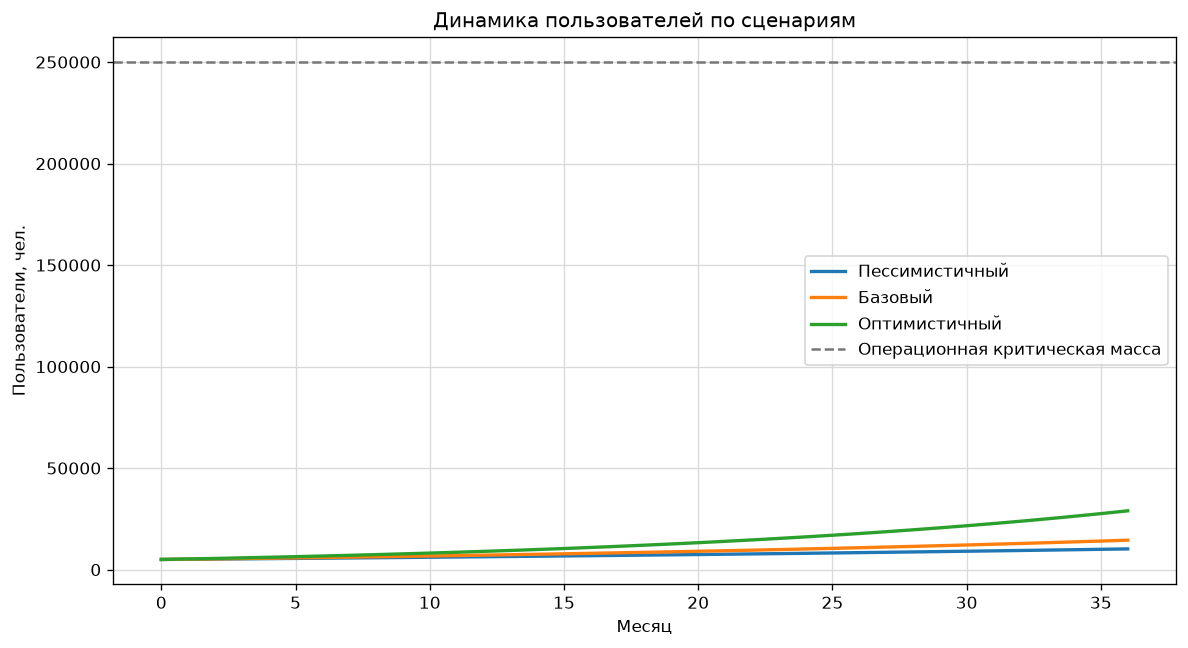

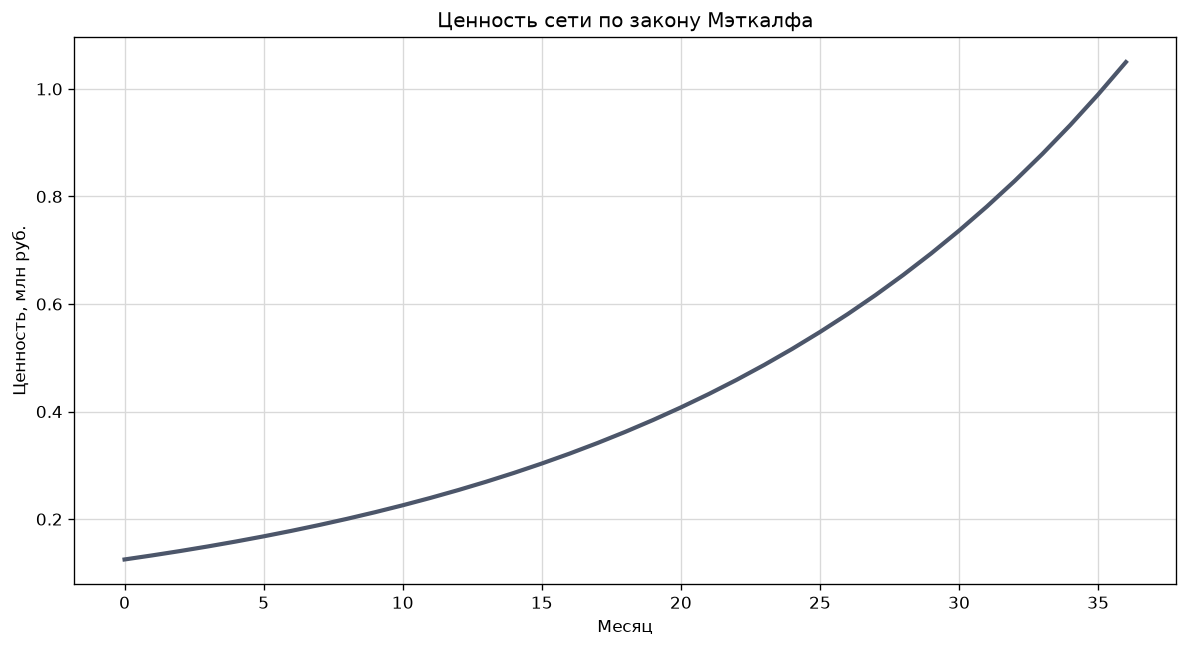

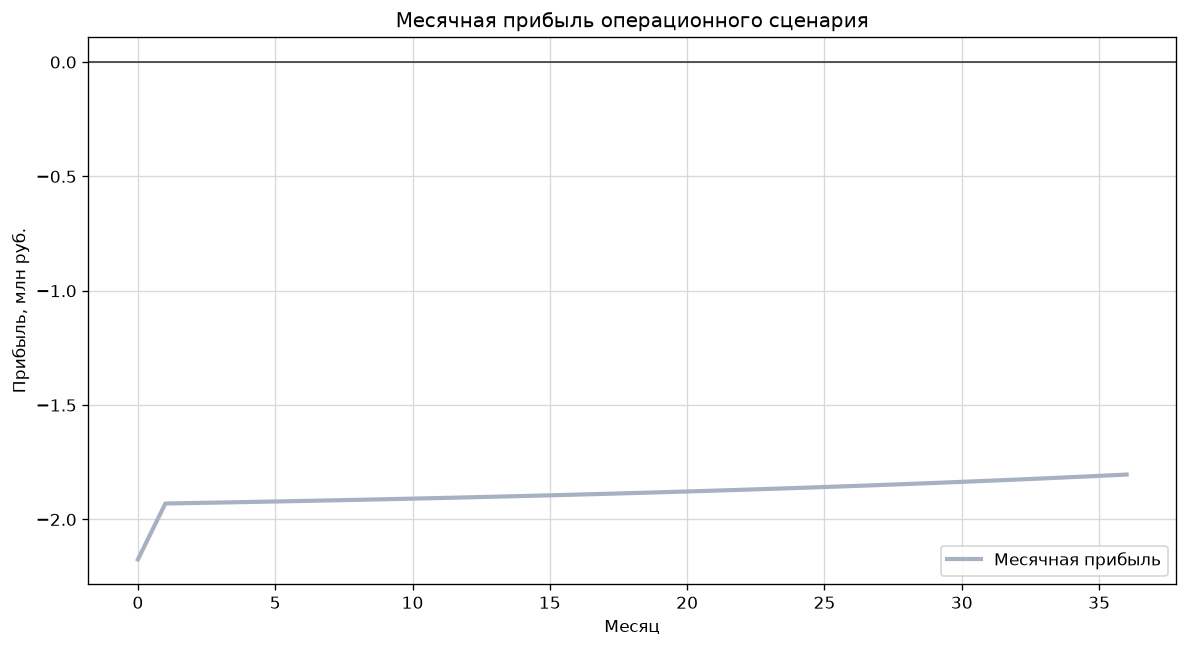

In [8]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for name, table in scenario_dfs.items():
    ax.plot(table["month"], table["users"], linewidth=2, label=name)
ax.axhline(operational_critical, linestyle="--", color="#777777", label="Операционная критическая масса")
ax.set(title="Динамика пользователей по сценариям", xlabel="Месяц", ylabel="Пользователи, чел.")
ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / "task_02_users_scenarios.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(df["month"], df["network_value"] / 1e6, color="#4C566A", linewidth=2.5)
ax.set(title="Ценность сети по закону Мэткалфа", xlabel="Месяц", ylabel="Ценность, млн руб.")
fig.tight_layout()
fig.savefig(figures_dir / "task_02_network_value.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(df["month"], df["profit"] / 1e6, color="#A7B1C2", linewidth=2.5, label="Месячная прибыль")
ax.axhline(0, color="#343A40", linewidth=1)
ax.set(title="Месячная прибыль операционного сценария", xlabel="Месяц", ylabel="Прибыль, млн руб.")
ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / "task_02_profit.png", bbox_inches="tight")
plt.show()

## Часть 4. Стратегические выводы

### Вопрос 9
Какой объём маркетинговых инвестиций необходим, чтобы достичь критической массы на шесть месяцев раньше?

### Вопрос 10
Сформулируйте рекомендации по стратегии достижения критической массы для «ГородСоцСеть».

**Расчёт и ответы.** Ниже рассчитаны дополнительные пользователи и бюджет ускорения, после чего сформулированы рекомендации по снижению CAC, повышению ARPU и поэтапному запуску.

In [9]:
base_target_month = months_to_target(operational_critical, cfg["growth_before_critical"], cfg["initial_users"])
earlier_month = max(1, base_target_month - 6)
base_users_at_target = cfg["initial_users"] * (1 + cfg["growth_before_critical"]) ** earlier_month
required_users = operational_critical
additional_users = max(required_users - base_users_at_target, 0)
marketing_investment = additional_users * operational_cac
strategy_table = pd.DataFrame({
    "Показатель": ["Базовый месяц достижения операционной критической массы", "Целевой месяц (на 6 месяцев раньше)", "Пользователи в целевом месяце без ускорения", "Дополнительные пользователи", "Маркетинговые инвестиции при CAC = 50 руб."],
    "Значение": [base_target_month, earlier_month, base_users_at_target, additional_users, marketing_investment],
    "Единица": ["мес.", "мес.", "чел.", "чел.", "руб."]
})
display(strategy_table)

final_table = pd.DataFrame({"Показатель": ["Строгая критическая масса при CAC = 500", "Операционная критическая масса: точное значение 233 333; в расчётах принято 250 000", "Строгий NPV за 36 мес.", "Операционный NPV за 36 мес.", "Безубыточный ARPU операционного сценария"], "Значение": [strict_critical_display, operational_critical, strict_npv, base_npv, break_even_arpu], "Единица": ["чел.", "чел.", "руб.", "руб.", "руб./пользователь/мес."]})
display(final_table)

,Показатель,Значение,Единица
0,Базовый месяц достижения операционной критичес...,"133,00",мес.
1,Целевой месяц (на 6 месяцев раньше),"127,00",мес.
2,Пользователи в целевом месяце без ускорения,"213 450,68",чел.
3,Дополнительные пользователи,"36 549,32",чел.
4,Маркетинговые инвестиции при CAC = 50 руб.,"1 827 466,02",руб.


,Показатель,Значение,Единица
0,Строгая критическая масса при CAC = 500,"1 133 333,33",чел.
1,Операционная критическая масса: точное значени...,"250 000,00",чел.
2,Строгий NPV за 36 мес.,"-60 099 621,18",руб.
3,Операционный NPV за 36 мес.,"-56 637 954,44",руб.
4,Безубыточный ARPU операционного сценария,"229,45",руб./пользователь/мес.


## Заключение

Модель показывает, что при исходном CAC = 500 руб. и ARPU = 15 руб. социальная сеть не достигает критической массы внутри рынка в 1 млн жителей. Основной рычаг изменения результата — снижение стоимости привлечения пользователя. В операционном сценарии с CAC = 50 руб. можно анализировать достижение критической массы, сетевую ценность и NPV, однако запуск следует осуществлять поэтапно с проверкой фактических когортных показателей.

**Ограничения:** закон Мэткалфа является упрощённой оценкой потенциальной сетевой ценности; оборот и выручка не равны прибыли без учёта маржи; модель не учитывает отток, сезонность, налоги, капитальные затраты, поддержку инфраструктуры сверх заданной суммы и изменение CAC по мере масштабирования.

In [10]:
%%capture
# Экспорт выполненного Notebook в HTML-отчёт
!python -m jupyter nbconvert --to html --no-input --output-dir ../reports --output task_02_report task_02_social_network.ipynb